
# Parte 1 - Análise Exploratória de Dados (EDA)

## Klike Data Science Challenge

### Objetivo

Analisar as características dos criativos de campanhas publicitárias em vídeo e identificar padrões associados às métricas de performance.

A análise busca responder:

1. Qual é o perfil geral do dataset?
2. Quais características dos criativos estão associadas a melhores resultados?
3. Existem diferenças de desempenho entre Meta, TikTok e LinkedIn?
4. Quais insights podem orientar decisões de marketing?


In [44]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [45]:
# Estilo visual dos gráficos
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

# Configurações gerais dos gráficos
plt.rcParams["figure.dpi"] = 125
plt.rcParams["savefig.dpi"] = 180

# Remover bordas superiores e direitas
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# Caminho do dataset
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "klike_challenge_dataset.csv"

# Caminho para salvar as imagens
FIGURES_PATH = PROJECT_ROOT / "img"

In [46]:
# Carregar o dataset
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"]
)

print("Dataset carregado com sucesso!")


Dataset carregado com sucesso!


# 1- Perfil Geral dos dados

## 1.1 - Visão geral do dataset

Antes de explorar as relações entre as características dos criativos e as métricas de performance, é necessário compreender a estrutura dos dados.

Nesta etapa, serão avaliados:

- Quantidade de registros e variáveis;
- Período de veiculação das campanhas;
- Primeiras observações do dataset;
- Tipos de dados;
- Valores ausentes e duplicados.


In [47]:
# Quantidade de linhas e colunas
n_linhas = df.shape[0]
n_colunas = df.shape[1]

print(f"Quantidade de campanhas: {n_linhas}")
print(f"Quantidade de variáveis: {n_colunas}")


Quantidade de campanhas: 500
Quantidade de variáveis: 26


In [48]:
# Identificar o período coberto pelo dataset
data_inicial = df["date"].min()
data_final = df["date"].max()

print(f"Data inicial: {data_inicial:%d/%m/%Y}")
print(f"Data final: {data_final:%d/%m/%Y}")


Data inicial: 01/01/2024
Data final: 30/12/2024


In [49]:
# Visualizar as cinco primeiras campanhas
display(df.head())


,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,...,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,...,5882,0.0390,0.82,4823.24,48,0.00,0.00,3.9,0.0446,63.6
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,...,493,0.0664,3.54,1745.22,34,NaN,0.16,6.4,0.0217,70.0
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,...,15069,0.0780,0.38,5726.22,492,51053.44,8.92,8.0,0.1000,99.1
3,KLK-0004,2024-12-27,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,...,601,0.0925,0.71,426.71,19,1113.78,2.61,20.3,0.0414,74.9
4,KLK-0005,2024-07-10,Meta,Branding,engagement,25-34,False,34.0,vertical,True,...,2355,0.0369,0.38,894.90,13,0.00,0.00,34.0,0.0184,77.9


In [50]:
# Verificar tipos de dados e valores não nulos
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   campaign_id          500 non-null    object        
 1   date                 500 non-null    datetime64[ns]
 2   platform             500 non-null    object        
 3   category             500 non-null    object        
 4   objective            500 non-null    object        
 5   target_audience_age  500 non-null    object        
 6   is_retargeting       500 non-null    bool          
 7   video_duration_s     461 non-null    float64       
 8   format               500 non-null    object        
 9   has_subtitle         454 non-null    object        
 10  has_cta              500 non-null    bool          
 11  has_hook             500 non-null    bool          
 12  has_face             500 non-null    bool          
 13  text_density         500 non-null  

## 1.2 - Análise da qualidade dos dados

Nesta etapa, serão investigados possíveis problemas de qualidade que possam comprometer a análise e a modelagem preditiva.

Serão avaliados:

- Valores ausentes e sua distribuição;
- Registros duplicados;
- Inconsistências entre variáveis;
- Valores extremos (outliers).

O objetivo é identificar problemas e definir estratégias de tratamento, preservando informações relevantes para a análise de performance das campanhas.


In [51]:
# Contar valores ausentes por variável
valores_ausentes = df.isnull().sum()

# Calcular o percentual de valores ausentes
percentual_ausentes = (
    df.isnull().mean() * 100
)

# Criar uma tabela com os resultados
tabela_ausentes = pd.DataFrame({
    "Valores ausentes": valores_ausentes,
    "Percentual (%)": percentual_ausentes
})

# Mostrar apenas variáveis com dados ausentes
tabela_ausentes = tabela_ausentes[
    tabela_ausentes["Valores ausentes"] > 0
]

# Ordenar do maior para o menor percentual
tabela_ausentes = tabela_ausentes.sort_values(
    by="Percentual (%)",
    ascending=False
)

display(tabela_ausentes)


,Valores ausentes,Percentual (%)
has_subtitle,46,9.2
video_duration_s,39,7.8
music_voice_ratio,38,7.6
engagement_rate,32,6.4
cpc,28,5.6
avg_watch_time_s,27,5.4
revenue,25,5.0


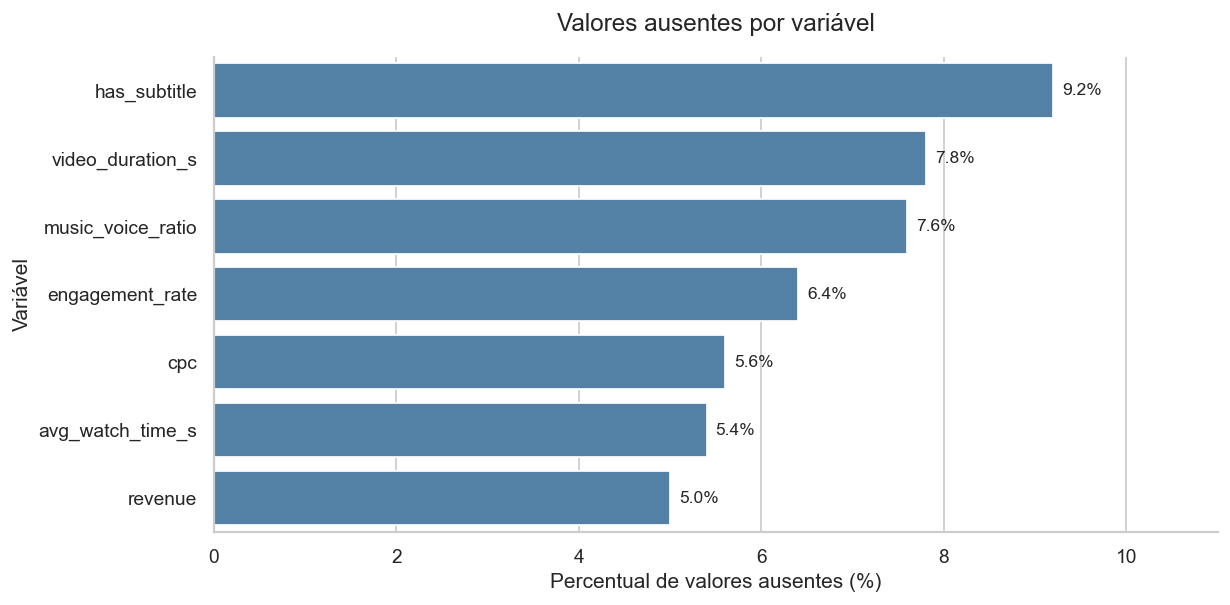

In [56]:

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=tabela_ausentes.reset_index(),
    x="Percentual (%)",
    y="index",
    color="steelblue",
    ax=ax
)

# Adicionar percentuais às barras
for barra in ax.patches:
    largura = barra.get_width()

    ax.text(
        largura + 0.1,
        barra.get_y() + barra.get_height() / 2,
        f"{largura:.1f}%",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Valores ausentes por variável",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Percentual de valores ausentes (%)")
ax.set_ylabel("Variável")
ax.set_xlim(0, 11)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "valores_ausentes.png",
    bbox_inches="tight"
)

plt.show()


### 1.2.1 - Interpretação dos valores ausentes

Foram identificados valores ausentes em sete variáveis do dataset.

A variável `has_subtitle` apresentou a maior proporção de dados ausentes (9,2%), seguida de `video_duration_s` (7,8%) e `music_voice_ratio` (7,6%).

**Estratégia de tratamento:**

- Preservar os registros durante a análise exploratória.
- Avaliar a imputação pela mediana para variáveis numéricas.
- Considerar uma categoria específica para valores ausentes em variáveis categóricas.
- Investigar possíveis relações entre os dados ausentes e outras características das campanhas.

A imputação será implementada posteriormente no pipeline de modelagem, evitando vazamento de informações entre treino e teste.


## 1.3 - Análise de registros duplicados

Registros duplicados podem distorcer estatísticas descritivas e influenciar indevidamente o treinamento de modelos.

Serão investigadas duplicatas completas e identificadores de campanhas repetidos.


In [53]:
# Contar linhas completamente duplicadas
duplicatas_completas = df.duplicated().sum()

# Contar identificadores de campanha duplicados
duplicatas_id = df["campaign_id"].duplicated().sum()

print("Duplicatas completas:", duplicatas_completas)
print("IDs de campanha duplicados:", duplicatas_id)


Duplicatas completas: 0
IDs de campanha duplicados: 0


## 1.4 - Identificação de outliers

Outliers são observações que apresentam valores muito diferentes da maior parte dos dados.

Em campanhas publicitárias, valores extremos podem representar campanhas com grandes investimentos, maior alcance ou resultados excepcionalmente altos.

Para identificar possíveis outliers, será utilizado o método do intervalo interquartil (IQR).

Um valor será considerado potencialmente atípico quando estiver abaixo de Q1 - 1,5 × IQR ou acima de Q3 + 1,5 × IQR.

A identificação de outliers não implica sua remoção automática.


In [54]:
# Selecionar métricas numéricas para análise
metricas = [
    "impressions",
    "clicks",
    "spend",
    "conversions",
    "ctr",
    "cpc",
    "roas",
    "video_duration_s"
]

# Armazenar os resultados
resultados_outliers = []

for coluna in metricas:

    # Calcular quartis
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)

    # Calcular intervalo interquartil
    iqr = q3 - q1

    # Definir limites
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    # Identificar valores fora dos limites
    outliers = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    )

    # Armazenar resultados
    resultados_outliers.append({
        "Variável": coluna,
        "Quantidade de outliers": outliers.sum(),
        "Percentual (%)": outliers.mean() * 100
    })

# Construir tabela
tabela_outliers = pd.DataFrame(resultados_outliers)

display(tabela_outliers)


,Variável,Quantidade de outliers,Percentual (%)
0,impressions,45,9.0
1,clicks,49,9.8
2,spend,61,12.2
3,conversions,61,12.2
4,ctr,0,0.0
5,cpc,66,13.2
6,roas,27,5.4
7,video_duration_s,17,3.4


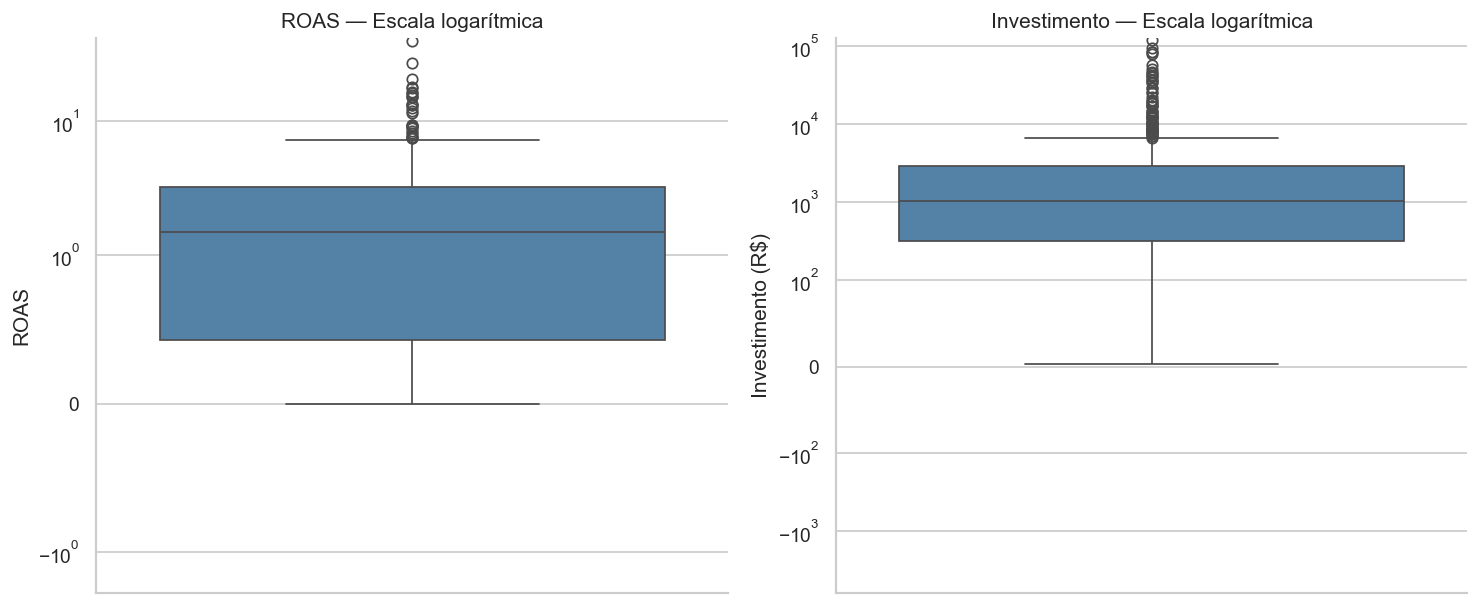

In [57]:

# Criar figura
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5)
)

# ROAS em escala logarítmica
sns.boxplot(
    data=df,
    y="roas",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_yscale("symlog", linthresh=1)
axes[0].set_title("ROAS — Escala logarítmica")
axes[0].set_ylabel("ROAS")

# SPEND em escala logarítmica
sns.boxplot(
    data=df,
    y="spend",
    color="steelblue",
    ax=axes[1]
)

axes[1].set_yscale("symlog", linthresh=100)
axes[1].set_title("Investimento — Escala logarítmica")
axes[1].set_ylabel("Investimento (R$)")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "outliers_escala_log.png",
    bbox_inches="tight"
)

plt.show()



### 1.4.1 - Tratamento de outliers

A análise pelo método IQR permite identificar observações potencialmente extremas nas métricas de performance.

Entretanto, em dados de marketing, campanhas com gastos ou resultados muito elevados não representam necessariamente erros.

Por esse motivo, os outliers serão inicialmente preservados.

As estratégias consideradas para etapas posteriores incluem:

- Investigar valores incompatíveis com as definições das métricas.
- Utilizar transformações logarítmicas para variáveis muito assimétricas, quando apropriado.
- Avaliar modelos menos sensíveis a valores extremos.
- Comparar os resultados com e sem tratamentos específicos, caso necessário.

Não será realizada remoção automática de observações apenas com base no IQR.


## 1.5 - Análise das distribuições

Nesta seção, serão analisadas as distribuições das variáveis numéricas e categóricas para compreender o perfil das campanhas.

A análise tem como objetivos:

- Identificar as plataformas e categorias mais representadas;
- Compreender a distribuição dos objetivos das campanhas;
- Avaliar as medidas de tendência central e dispersão;
- Identificar assimetrias nas métricas de performance;
- Investigar possíveis diferenças de escala entre campanhas.

Essas informações servirão como base para as análises posteriores de correlação e comparação entre plataformas.


### 1.5.1 - Estatísticas descritivas das variáveis numéricas

Inicialmente, serão analisadas as principais estatísticas descritivas das variáveis numéricas do dataset.

Serão observadas medidas de tendência central, dispersão e posição, permitindo compreender as características gerais das campanhas e identificar possíveis assimetrias.

Essa análise complementa a investigação anterior de valores ausentes e outliers.


In [58]:
# Selecionar as variáveis numéricas
colunas_numericas = df.select_dtypes(
    include=["number"]
).columns

# Calcular estatísticas descritivas
estatisticas_descritivas = df[
    colunas_numericas
].describe()

# Exibir os resultados
display(estatisticas_descritivas)


,video_duration_s,music_voice_ratio,impressions,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
count,461.000000,462.000000,5.000000e+02,500.000000,500.000000,472.000000,500.000000,500.0000,475.000000,500.000000,473.000000,468.000000,500.0000
mean,19.392625,0.399848,1.537385e+05,3594.104000,0.070968,1.112903,4213.151620,131.3520,6367.936863,2.499000,10.664271,0.027952,60.1568
std,13.529351,0.202674,1.171736e+06,7018.212512,0.045302,1.955625,11573.975576,314.5654,19267.180696,3.592365,10.533275,0.023057,15.5891
min,5.000000,0.020000,1.000000e+03,4.000000,0.002200,0.050000,2.960000,0.0000,0.000000,0.000000,0.400000,0.001000,10.4000
25%,11.000000,0.230000,9.986000e+03,461.750000,0.033200,0.530000,313.452500,10.0000,262.175000,0.430000,4.700000,0.011100,49.7750
50%,16.000000,0.385000,2.324100e+04,1351.000000,0.062750,0.710000,1031.000000,34.5000,1201.050000,1.490000,7.700000,0.021400,60.5500
75%,25.000000,0.550000,5.517275e+04,3583.250000,0.104800,1.020000,2867.952500,111.0000,4189.025000,3.250000,13.900000,0.038800,71.9250
max,115.000000,0.920000,1.405276e+07,72545.000000,0.150000,26.050000,121226.100000,3666.0000,241597.290000,39.920000,108.000000,0.100000,99.1000


In [59]:
# Selecionar métricas principais
metricas_performance = [
    "ctr",
    "roas",
    "cpc",
    "spend",
    "conversions",
    "klike_score"
]

# Calcular média e mediana
resumo_metricas = df[
    metricas_performance
].agg(["mean", "median", "std", "min", "max"])

# Transpor a tabela
resumo_metricas = resumo_metricas.T

# Arredondar resultados
resumo_metricas = resumo_metricas.round(2)

display(resumo_metricas)


,mean,median,std,min,max
ctr,0.07,0.06,0.05,0.00,0.15
roas,2.50,1.49,3.59,0.00,39.92
cpc,1.11,0.71,1.96,0.05,26.05
spend,4213.15,1031.00,11573.98,2.96,121226.10
conversions,131.35,34.50,314.57,0.00,3666.00
klike_score,60.16,60.55,15.59,10.40,99.10



### 1.5.2 - Distribuição das variáveis categóricas

Nesta etapa, serão analisadas as frequências das principais variáveis categóricas:

- Plataforma de veiculação (`platform`);
- Categoria do anunciante (`category`);
- Objetivo da campanha (`objective`).

O objetivo é compreender a composição do dataset e identificar possíveis desequilíbrios entre os grupos de campanhas.


In [60]:
# Contar campanhas por plataforma
contagem_plataformas = df[
    "platform"
].value_counts()

# Calcular proporção percentual
percentual_plataformas = df[
    "platform"
].value_counts(normalize=True) * 100

# Criar tabela de distribuição
distribuicao_plataformas = pd.DataFrame({
    "Quantidade": contagem_plataformas,
    "Percentual (%)": percentual_plataformas
})

display(distribuicao_plataformas.round(2))


,Quantidade,Percentual (%)
platform,,
Meta,241,48.2
TikTok,176,35.2
LinkedIn,83,16.6


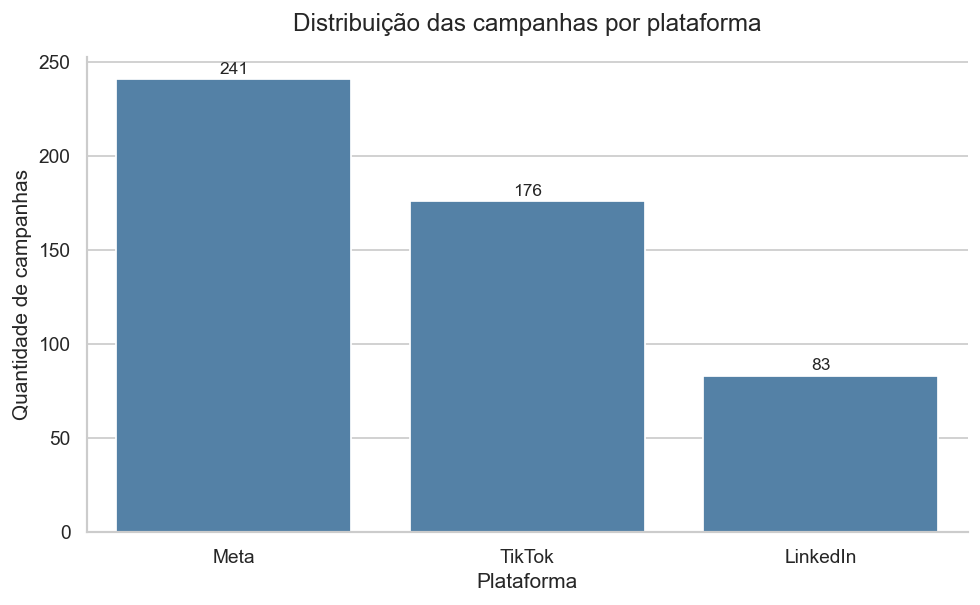

In [61]:
# Criar figura
fig, ax = plt.subplots(figsize=(8, 5))

# Gráfico de barras
sns.countplot(
    data=df,
    x="platform",
    order=df["platform"].value_counts().index,
    color="steelblue",
    ax=ax
)

# Adicionar quantidades acima das barras
for barra in ax.patches:
    altura = barra.get_height()

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 3,
        f"{int(altura)}",
        ha="center",
        fontsize=10
    )

# Personalização
ax.set_title(
    "Distribuição das campanhas por plataforma",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Plataforma")
ax.set_ylabel("Quantidade de campanhas")

plt.tight_layout()

# Salvar figura
plt.savefig(
    FIGURES_PATH / "distribuicao_plataformas.png",
    bbox_inches="tight"
)

plt.show()


In [62]:
# Distribuição das categorias
distribuicao_categorias = df[
    "category"
].value_counts()

print("Distribuição por categoria:")
display(distribuicao_categorias)

# Distribuição dos objetivos
distribuicao_objetivos = df[
    "objective"
].value_counts()

print("Distribuição por objetivo:")
display(distribuicao_objetivos)


Distribuição por categoria:


category
E-commerce     165
SaaS            97
Lead Gen        93
App Install     82
Branding        63
Name: count, dtype: int64

Distribuição por objetivo:


objective
conversions    165
traffic        150
engagement      79
awareness       60
app_install     46
Name: count, dtype: int64

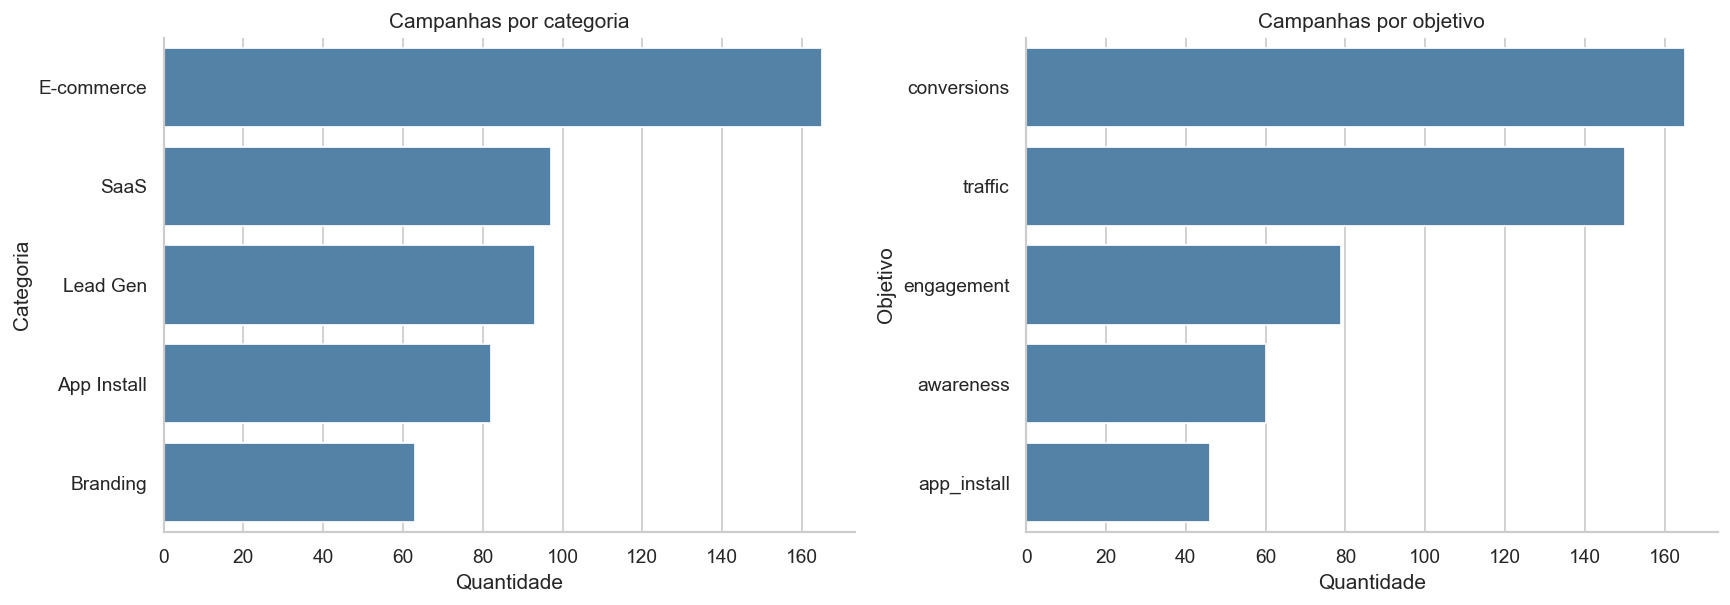

In [63]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

# Distribuição por categoria
sns.countplot(
    data=df,
    y="category",
    order=df["category"].value_counts().index,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Campanhas por categoria")
axes[0].set_xlabel("Quantidade")
axes[0].set_ylabel("Categoria")

# Distribuição por objetivo
sns.countplot(
    data=df,
    y="objective",
    order=df["objective"].value_counts().index,
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("Campanhas por objetivo")
axes[1].set_xlabel("Quantidade")
axes[1].set_ylabel("Objetivo")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "categorias_objetivos.png",
    bbox_inches="tight"
)

plt.show()


## 1.6 - Consistência das métricas

Além de valores ausentes e outliers, é importante verificar se as métricas de performance são coerentes entre si.

Nesta etapa, serão avaliadas três relações:

- CTR: razão entre cliques e impressões;
- CPC: razão entre investimento e cliques;
- ROAS: razão entre receita e investimento.

O objetivo é identificar possíveis inconsistências nos registros e avaliar sua relevância para as análises posteriores.


In [64]:
# Calcular métricas a partir das colunas originais
df_consistencia = df.copy()

df_consistencia["ctr_calculado"] = (
    df_consistencia["clicks"] /
    df_consistencia["impressions"].replace(0, np.nan)
)

df_consistencia["cpc_calculado"] = (
    df_consistencia["spend"] /
    df_consistencia["clicks"].replace(0, np.nan)
)

df_consistencia["roas_calculado"] = (
    df_consistencia["revenue"] /
    df_consistencia["spend"].replace(0, np.nan)
)


In [65]:
# Calcular diferenças absolutas
metricas = ["ctr", "cpc", "roas"]

for metrica in metricas:

    coluna_calculada = f"{metrica}_calculado"

    df_consistencia[f"dif_{metrica}"] = (
        df_consistencia[metrica] -
        df_consistencia[coluna_calculada]
    ).abs()

# Resumir as diferenças
resumo_consistencia = df_consistencia[
    ["dif_ctr", "dif_cpc", "dif_roas"]
].agg(["count", "mean", "median", "max"])

display(resumo_consistencia)


,dif_ctr,dif_cpc,dif_roas
count,500.000000,472.000000,475.000000
mean,0.000293,10.820754,0.031006
median,0.000017,0.000000,0.002115
max,0.042312,4790.314500,13.449242


## 1.7 - Principais conclusões

A análise exploratória inicial permitiu caracterizar o conjunto de campanhas publicitárias e identificar aspectos relevantes para as próximas etapas.

**Principais observações:**

1. **Composição do dataset:** a base contém 500 campanhas, distribuídas entre Meta, TikTok e LinkedIn, com diferentes categorias, objetivos e características de criativos.

2. **Valores ausentes:** foram identificadas sete variáveis com dados faltantes. A estratégia inicial consiste em preservar os registros e avaliar tratamentos apropriados durante o pré-processamento.

3. **Outliers:** algumas métricas, especialmente investimento e ROAS, apresentam distribuições assimétricas e valores extremos. Essas observações não serão removidas automaticamente, pois podem representar campanhas legítimas.

4. **Consistência das métricas:** as diferenças entre métricas registradas e recalculadas apresentaram medianas pequenas, mas também divergências máximas expressivas, principalmente em CPC e ROAS. Esses casos exigem investigação antes de eventuais correções.

**Decisões metodológicas:**

- Não excluir automaticamente registros com valores ausentes ou extremos.
- Preservar o dataset original.
- Realizar tratamentos de dados dentro do pipeline de modelagem, quando apropriado.
- Considerar diferenças de escala e assimetria nas análises de performance.

Essas decisões buscam preservar informações relevantes e reduzir o risco de introduzir distorções na análise.


# 2 - Atributos × Performance

Nesta etapa, serão investigadas as relações entre características dos criativos publicitários e as principais métricas de performance.

Serão consideradas:

**Características dos criativos:**
- Presença de hook nos primeiros três segundos;
- Presença de call-to-action (CTA);
- Utilização de legendas;
- Presença de rosto humano;
- Duração e formato do vídeo;
- Densidade de texto.

**Métricas de performance:**
- CTR (Click-Through Rate);
- ROAS (Return on Ad Spend);
- Número de conversões;
- Taxa de engajamento.

O objetivo é identificar padrões que possam apoiar decisões de otimização dos criativos.

As relações observadas serão interpretadas como associações estatísticas, não como evidências de causalidade.


## 2.1 - Características binárias e métricas de performance

Nesta análise, serão comparadas as métricas médias de campanhas com e sem determinadas características dos criativos.

Os atributos avaliados serão:

- `has_hook`;
- `has_cta`;
- `has_face`;
- `has_subtitle`.

A comparação permite investigar se a presença de cada característica está associada a diferenças de performance.

Inicialmente, será realizada uma análise agregada, sem controle por plataforma, categoria ou objetivo da campanha.


In [66]:
# Características binárias dos criativos
atributos_binarios = [
    "has_hook",
    "has_cta",
    "has_face",
    "has_subtitle"
]

# Métricas de performance
metricas_performance = [
    "ctr",
    "roas",
    "conversions",
    "engagement_rate"
]


In [67]:
# Armazenar resultados das comparações
resultados_atributos = []

for atributo in atributos_binarios:

    # Agrupar campanhas pela presença do atributo
    agrupamento = df.groupby(atributo)

    # Calcular médias das métricas
    medias = agrupamento[
        metricas_performance
    ].mean()

    # Calcular quantidade de campanhas
    quantidades = agrupamento.size()

    # Organizar resultados
    for valor in medias.index:

        resultado = {
            "Atributo": atributo,
            "Presente": valor,
            "Quantidade": quantidades.loc[valor]
        }

        for metrica in metricas_performance:
            resultado[metrica] = medias.loc[
                valor,
                metrica
            ]

        resultados_atributos.append(resultado)

# Converter para DataFrame
tabela_atributos = pd.DataFrame(resultados_atributos)

display(tabela_atributos.round(4))


,Atributo,Presente,Quantidade,ctr,roas,conversions,engagement_rate
0,has_hook,False,244,0.0591,2.5902,127.4426,0.0253
1,has_hook,True,256,0.0823,2.4121,135.0781,0.0304
2,has_cta,False,153,0.0669,2.5329,120.9804,0.0291
3,has_cta,True,347,0.0728,2.4840,135.9251,0.0274
4,has_face,False,231,0.0632,2.6092,113.4372,0.0232
5,has_face,True,269,0.0776,2.4044,146.7361,0.0321
6,has_subtitle,False,191,0.0681,2.4807,134.6387,0.0285
7,has_subtitle,True,263,0.0743,2.6612,127.8289,0.0273


In [68]:
resultados_impacto = []

for atributo in atributos_binarios:

    # Selecionar campanhas com e sem o atributo
    sem_atributo = df[df[atributo] == False]
    com_atributo = df[df[atributo] == True]

    resultado = {
        "Atributo": atributo,
        "N_sem": len(sem_atributo),
        "N_com": len(com_atributo)
    }

    for metrica in metricas_performance:

        media_sem = sem_atributo[metrica].mean()
        media_com = com_atributo[metrica].mean()

        # Calcular diferença percentual relativa
        if pd.notna(media_sem) and media_sem != 0:
            diferenca = (
                (media_com - media_sem) / abs(media_sem)
            ) * 100
        else:
            diferenca = np.nan

        resultado[f"{metrica}_diff_pct"] = diferenca

    resultados_impacto.append(resultado)

# Criar tabela comparativa
tabela_impacto = pd.DataFrame(resultados_impacto)

display(tabela_impacto.round(2))


,Atributo,N_sem,N_com,ctr_diff_pct,roas_diff_pct,conversions_diff_pct,engagement_rate_diff_pct
0,has_hook,244,256,39.22,-6.87,5.99,20.27
1,has_cta,153,347,8.82,-1.93,12.35,-5.86
2,has_face,231,269,22.83,-7.85,29.35,38.21
3,has_subtitle,191,263,9.19,7.28,-5.06,-4.42


## 2.2 - Visualização das diferenças de CTR

Para facilitar a interpretação dos resultados, será construído um gráfico comparando o CTR médio das campanhas com e sem determinadas características dos criativos.

O objetivo é comunicar quais atributos estão associados a diferenças mais expressivas na taxa de cliques.


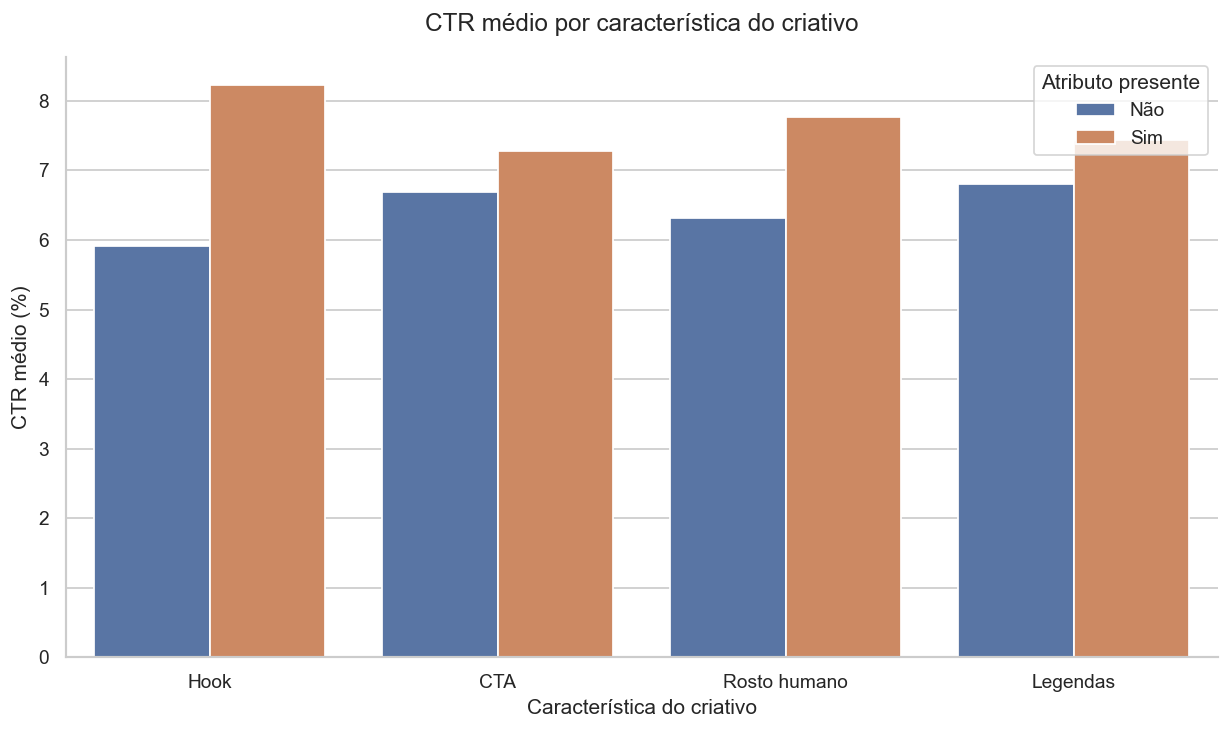

In [70]:
# Preparar dados para visualização
dados_grafico = tabela_atributos.copy()

# Converter CTR para porcentagem
dados_grafico["CTR (%)"] = (
    dados_grafico["ctr"] * 100
)

# Melhorar nomes dos atributos
nomes_atributos = {
    "has_hook": "Hook",
    "has_cta": "CTA",
    "has_face": "Rosto humano",
    "has_subtitle": "Legendas"
}

dados_grafico["Atributo"] = (
    dados_grafico["Atributo"].replace(nomes_atributos)
)

# Criar figura
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=dados_grafico,
    x="Atributo",
    y="CTR (%)",
    hue="Presente",
    ax=ax
)

# Personalização
ax.set_title(
    "CTR médio por característica do criativo",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Característica do criativo")
ax.set_ylabel("CTR médio (%)")

handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles=handles,
    labels=["Não", "Sim"],
    title="Atributo presente"
)
plt.tight_layout()

# Salvar imagem
plt.savefig(
    FIGURES_PATH / "ctr_atributos.png",
    bbox_inches="tight"
)

plt.show()



### 2.2.1 - Interpretação dos resultados

A comparação entre características binárias dos criativos revelou diferenças relevantes nas métricas de performance.

**Presença de hook**

Campanhas com hook nos primeiros três segundos apresentaram CTR médio de 8,23%, contra 5,91% nas campanhas sem hook, representando uma diferença relativa de aproximadamente 39,22%.

Apesar disso, o ROAS médio das campanhas com hook foi 6,87% inferior.

**Presença de rosto humano**

Campanhas com rosto humano apresentaram CTR médio 22,83% superior e número médio de conversões 29,35% maior.

Entretanto, o ROAS médio foi 7,85% inferior ao das campanhas sem essa característica.

**Presença de CTA**

Campanhas com CTA apresentaram CTR médio 8,82% superior e número médio de conversões 12,35% maior.

**Utilização de legendas**

Campanhas com legendas apresentaram CTR médio 9,19% superior e ROAS médio 7,28% maior. Entretanto, tiveram número médio de conversões 5,06% menor.

**Conclusão preliminar**

Os resultados sugerem que diferentes atributos dos criativos estão associados a diferentes dimensões de performance.

Características relacionadas à atenção e à interação podem apresentar associações positivas com o CTR sem necessariamente apresentar a mesma relação com o retorno financeiro.

Essas comparações são descritivas e não controlam diferenças de plataforma, categoria, objetivo ou investimento. Portanto, não devem ser interpretadas como efeitos causais.


## 2.3 - Duração, formato e densidade de texto

Após analisar as características binárias, esta seção investiga atributos relacionados à estrutura e ao conteúdo dos vídeos.

Serão avaliadas as relações entre duração, formato, densidade de texto e proporção de música/voz com as métricas de performance.

Para as características categóricas, serão comparadas médias entre grupos. Para as características numéricas, serão utilizadas análises de correlação.

O objetivo é identificar padrões que possam orientar futuras recomendações de otimização dos criativos.


In [71]:
# Selecionar características numéricas dos criativos
atributos_numericos = [
    "video_duration_s",
    "music_voice_ratio"
]

# Selecionar métricas de performance
metricas_performance = [
    "ctr",
    "roas",
    "conversions",
    "engagement_rate"
]

# Calcular correlação de Spearman
correlacoes = df[
    atributos_numericos + metricas_performance
].corr(method="spearman")

# Selecionar apenas relações de interesse
correlacoes_atributos = correlacoes.loc[
    atributos_numericos,
    metricas_performance
]

display(correlacoes_atributos.round(3))


,ctr,roas,conversions,engagement_rate
video_duration_s,0.000,-0.130,-0.016,-0.131
music_voice_ratio,0.037,-0.024,0.024,0.065


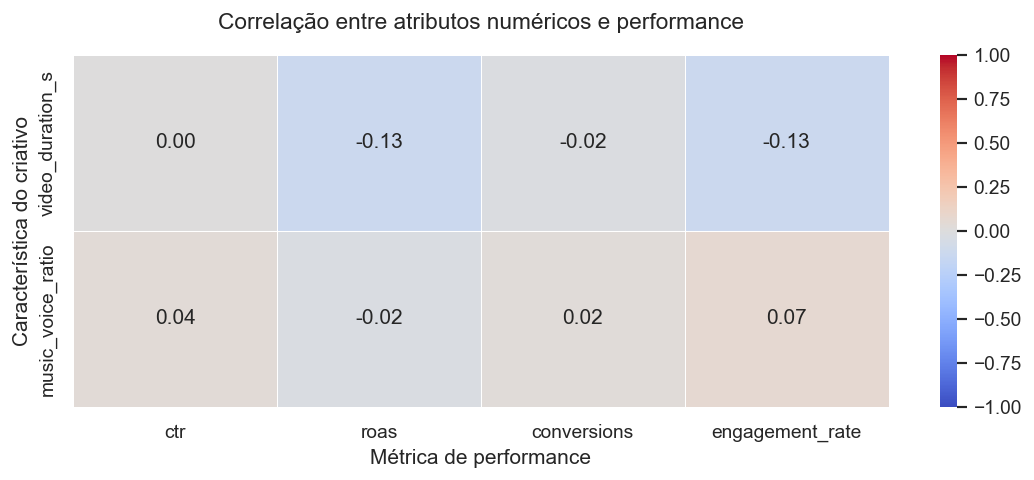

In [72]:
fig, ax = plt.subplots(figsize=(9, 4))

sns.heatmap(
    correlacoes_atributos,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    "Correlação entre atributos numéricos e performance",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Métrica de performance")
ax.set_ylabel("Característica do criativo")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "correlacoes_atributos.png",
    bbox_inches="tight"
)

plt.show()


In [73]:
# Características categóricas
atributos_categoricos = [
    "format",
    "text_density"
]

for atributo in atributos_categoricos:

    print(f"\nAnálise de {atributo}")

    # Agrupar campanhas por categoria
    resumo = df.groupby(
        atributo,
        dropna=False
    )[metricas_performance].agg(
        ["mean", "count"]
    )

    display(resumo.round(3))



Análise de format


ctr         roas       conversions       engagement_rate      
             mean count   mean count        mean count            mean count
format                                                                      
horizontal  0.075   111  1.330   111     143.730   111           0.020   104
quadrado    0.073   120  2.908   120     118.217   120           0.024   109
vertical    0.068   269  2.799   269     132.104   269           0.033   255


Análise de text_density


ctr         roas       conversions       engagement_rate      
               mean count   mean count        mean count            mean count
text_density                                                                  
high          0.060    91  2.097    91     131.099    91           0.027    88
low           0.074   179  2.797   179     133.520   179           0.028   167
medium        0.073   230  2.426   230     129.765   230           0.028   213


### 2.3.1 -Interpretação dos resultados

A análise das características estruturais dos vídeos revelou diferenças de performance conforme a duração, o formato e a densidade de texto.

**Duração do vídeo**

A duração apresentou correlação negativa fraca com ROAS (-0,130) e taxa de engajamento (-0,131). Não foi identificada correlação monotônica relevante com CTR (0,000).

**Proporção música/voz**

As correlações foram próximas de zero para todas as métricas analisadas, indicando ausência de associação monotônica expressiva no conjunto agregado.

**Formato do vídeo**

O formato horizontal apresentou maior CTR médio (7,5%), enquanto o quadrado apresentou maior ROAS médio (2,91). O formato vertical destacou-se na taxa média de engajamento (3,3%).

Esses resultados sugerem que diferentes formatos podem apresentar vantagens conforme a métrica priorizada.

**Densidade de texto**

Campanhas com baixa densidade de texto apresentaram CTR médio de 7,4% e ROAS médio de 2,80, superando os resultados observados nas campanhas com alta densidade de texto.

**Conclusão**

Os resultados indicam que as relações entre características dos criativos e performance variam conforme a métrica analisada.

As associações identificadas são exploratórias e não demonstram causalidade. A próxima etapa consiste em investigar se esses padrões se mantêm entre diferentes plataformas.



# 3 - Diferenças entre plataformas

Nesta etapa, serão investigadas as diferenças de performance entre Meta, TikTok e LinkedIn.

O objetivo é verificar se características associadas a bons resultados no conjunto geral apresentam comportamentos semelhantes nas diferentes plataformas.

Serão analisados:

- CTR, ROAS, conversões e engajamento por plataforma;
- Presença de hook e sua relação com performance;
- Duração dos vídeos;
- Formato e densidade de texto.

As comparações serão interpretadas considerando as diferenças de composição e tamanho das amostras.


In [74]:
# Métricas de performance
metricas_plataforma = [
    "ctr",
    "roas",
    "conversions",
    "engagement_rate",
    "klike_score"
]

# Calcular médias por plataforma
resumo_plataformas = df.groupby(
    "platform"
)[metricas_plataforma].mean()

# Adicionar quantidade de campanhas
resumo_plataformas.insert(
    0,
    "campanhas",
    df.groupby("platform").size()
)

# Exibir resultados
display(resumo_plataformas.round(3))


,campanhas,ctr,roas,conversions,engagement_rate,klike_score
platform,,,,,,
LinkedIn,83,0.071,1.128,158.892,0.021,56.308
Meta,241,0.072,2.176,137.564,0.022,60.395
TikTok,176,0.069,3.587,109.858,0.039,61.645


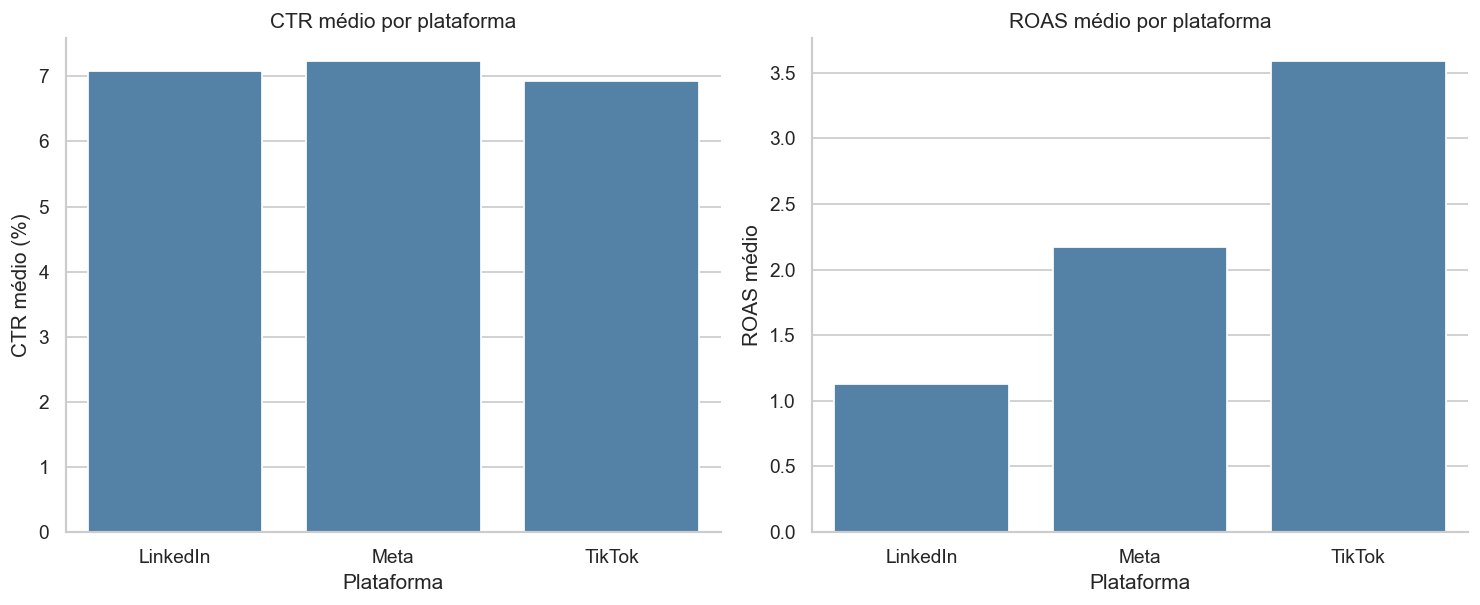

In [75]:
# Criar figura
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5)
)

# CTR médio em percentual
dados_ctr = resumo_plataformas.reset_index().copy()
dados_ctr["ctr_percentual"] = dados_ctr["ctr"] * 100

sns.barplot(
    data=dados_ctr,
    x="platform",
    y="ctr_percentual",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("CTR médio por plataforma")
axes[0].set_xlabel("Plataforma")
axes[0].set_ylabel("CTR médio (%)")
axes[0].set_ylim(bottom=0)

# ROAS médio
sns.barplot(
    data=dados_ctr,
    x="platform",
    y="roas",
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("ROAS médio por plataforma")
axes[1].set_xlabel("Plataforma")
axes[1].set_ylabel("ROAS médio")
axes[1].set_ylim(bottom=0)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "performance_plataformas.png",
    bbox_inches="tight"
)

plt.show()



### 3.1.1 - Interpretação da performance por plataforma

A comparação entre Meta, TikTok e LinkedIn revelou diferenças nas métricas de performance.

**CTR**

As três plataformas apresentaram taxas médias de cliques semelhantes, variando entre 6,9% e 7,2%.

O Meta registrou o maior CTR médio (7,2%), seguido por LinkedIn (7,1%) e TikTok (6,9%).

**ROAS**

O TikTok apresentou o maior ROAS médio (3,59), seguido por Meta (2,18) e LinkedIn (1,13).

Apesar da semelhança nas taxas de cliques, as diferenças no retorno financeiro foram expressivas.

**Conversões**

O LinkedIn apresentou o maior número médio de conversões por campanha (158,89), enquanto o TikTok apresentou o menor (109,86).

**Engajamento**

O TikTok destacou-se na taxa média de engajamento (3,9%), superando Meta (2,2%) e LinkedIn (2,1%).

**Conclusão preliminar**

Os resultados demonstram que plataformas com taxas de cliques semelhantes podem apresentar diferenças relevantes em retorno financeiro, conversões e engajamento.

Isso reforça a importância de considerar a plataforma e o objetivo da campanha ao avaliar a performance de criativos publicitários.

As diferenças observadas são descritivas e não devem ser interpretadas como efeitos causais da escolha da plataforma.


## 3.2 - Presença de hook e performance por plataforma

Nesta análise, será investigada a relação entre a presença de hook nos primeiros três segundos e as métricas de performance em cada plataforma.

Serão comparadas campanhas com e sem hook em Meta, TikTok e LinkedIn, considerando:

- CTR médio;
- ROAS médio;
- Quantidade de campanhas por grupo.

O objetivo é identificar se a associação entre hook e performance apresenta diferenças entre plataformas.

As comparações são observacionais e não permitem atribuir causalidade à presença do hook.


In [76]:
# Agrupar por plataforma e presença de hook
resumo_hook = df.groupby(
    ["platform", "has_hook"]
).agg(
    campanhas=("campaign_id", "count"),
    ctr_medio=("ctr", "mean"),
    roas_medio=("roas", "mean")
).reset_index()

# Converter CTR para porcentagem
resumo_hook["ctr_percentual"] = (
    resumo_hook["ctr_medio"] * 100
)

display(resumo_hook.round(3))


,platform,has_hook,campanhas,ctr_medio,roas_medio,ctr_percentual
0,LinkedIn,False,38,0.055,1.613,5.516
1,LinkedIn,True,45,0.084,0.719,8.408
2,Meta,False,113,0.061,2.482,6.114
3,Meta,True,128,0.082,1.907,8.212
4,TikTok,False,93,0.058,3.122,5.823
5,TikTok,True,83,0.082,4.109,8.154


In [77]:
# Organizar os valores em colunas separadas
comparacao_hook = resumo_hook.pivot(
    index="platform",
    columns="has_hook",
    values=["ctr_medio", "roas_medio"]
)

# Calcular a diferença relativa de CTR
diferenca_ctr = (
    (
        comparacao_hook[("ctr_medio", True)] -
        comparacao_hook[("ctr_medio", False)]
    ) /
    comparacao_hook[("ctr_medio", False)]
) * 100

# Calcular a diferença relativa de ROAS
diferenca_roas = (
    (
        comparacao_hook[("roas_medio", True)] -
        comparacao_hook[("roas_medio", False)]
    ) /
    comparacao_hook[("roas_medio", False)]
) * 100

# Criar tabela final
tabela_diferencas_hook = pd.DataFrame({
    "Diferença CTR (%)": diferenca_ctr,
    "Diferença ROAS (%)": diferenca_roas
})

display(tabela_diferencas_hook.round(2))


,Diferença CTR (%),Diferença ROAS (%)
platform,,
LinkedIn,52.44,-55.40
Meta,34.31,-23.15
TikTok,40.04,31.63


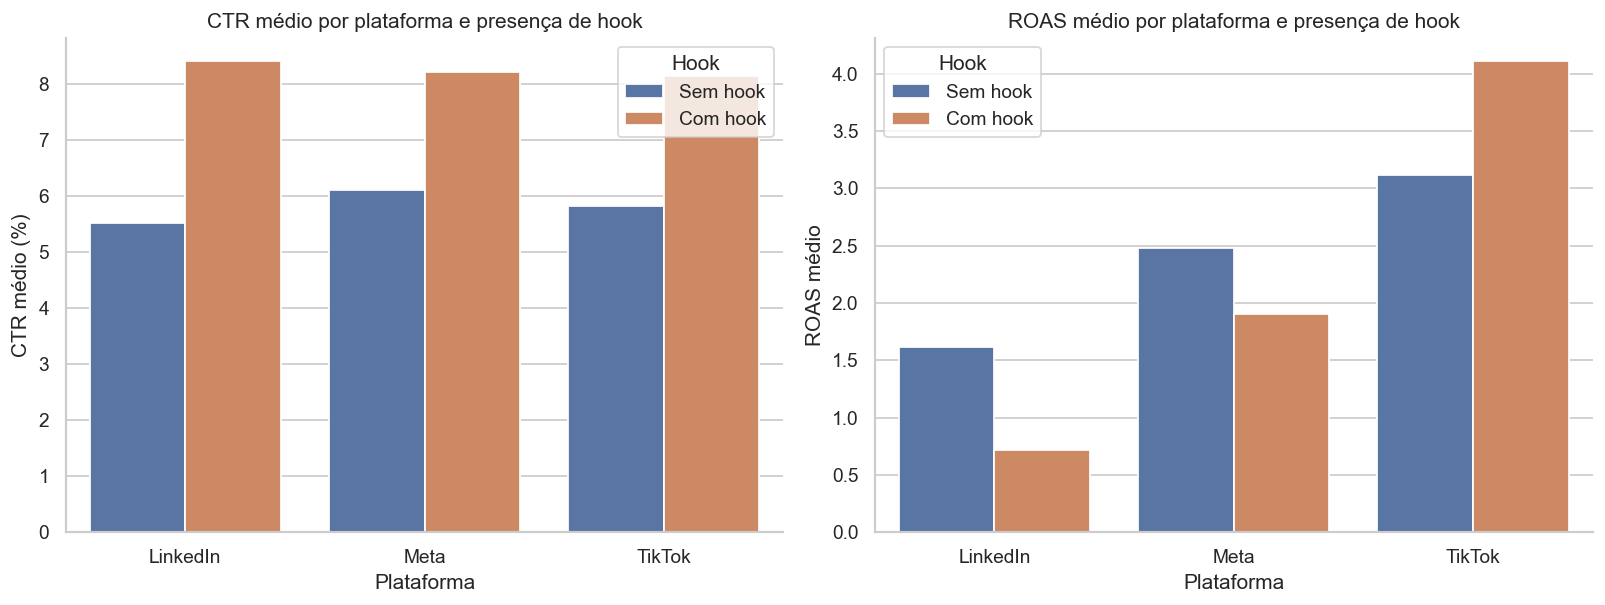

In [ ]:
# Criar figura
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5)
)

# CTR por plataforma e hook
sns.barplot(
    data=resumo_hook,
    x="platform",
    y="ctr_percentual",
    hue="has_hook",
    ax=axes[0]
)

axes[0].set_title("CTR médio por plataforma e presença de hook")
axes[0].set_xlabel("Plataforma")
axes[0].set_ylabel("CTR médio (%)")
axes[0].legend(title="Hook", labels=["Sem hook", "Com hook"])

# ROAS por plataforma e hook
sns.barplot(
    data=resumo_hook,
    x="platform",
    y="roas_medio",
    hue="has_hook",
    ax=axes[1]
)

axes[1].set_title("ROAS médio por plataforma e presença de hook")
axes[1].set_xlabel("Plataforma")
axes[1].set_ylabel("ROAS médio")
axes[1].legend(title="Hook", labels=["Sem hook", "Com hook"])

plt.tight_layout()

# Salvar gráfico
plt.savefig(
    FIGURES_PATH / "hook_por_plataforma.png",
    bbox_inches="tight"
)
handles, _ = axes[0].get_legend_handles_labels()
axes[0].legend(handles, ["Sem hook", "Com hook"], title="Hook")

handles, _ = axes[1].get_legend_handles_labels()
axes[1].legend(handles, ["Sem hook", "Com hook"], title="Hook")

plt.show()



### 3.2.1 - Interpretação 

A comparação entre campanhas com e sem hook revelou diferenças importantes entre as plataformas analisadas.

**CTR**

A presença de hook esteve associada a CTR médio superior nas três plataformas:

- LinkedIn: aproximadamente 5,5% sem hook e 8,4% com hook.
- Meta: aproximadamente 6,1% sem hook e 8,2% com hook.
- TikTok: aproximadamente 5,8% sem hook e 8,2% com hook.

Esse padrão sugere que a presença de hook pode estar relacionada à capacidade do criativo de atrair cliques, independentemente da plataforma.

**ROAS**

Em contraste com o CTR, a relação entre hook e ROAS apresentou comportamentos diferentes:

- TikTok: ROAS médio maior entre campanhas com hook.
- Meta: ROAS médio menor entre campanhas com hook.
- LinkedIn: ROAS médio consideravelmente menor entre campanhas com hook.

**Principal insight**

Os resultados mostram que uma característica associada a maior CTR não necessariamente está associada a maior retorno financeiro.

Além disso, a relação com o ROAS varia entre plataformas.

Esse resultado reforça a importância de desenvolver recomendações contextuais, considerando não apenas as características do criativo, mas também a plataforma e o objetivo da campanha.

**Limitações**

As comparações são observacionais e não controlam possíveis diferenças de público-alvo, categoria, investimento ou objetivo da campanha.

Portanto, não é possível concluir que adicionar ou remover um hook causaria as diferenças observadas.


## 3.3 - Formato do vídeo e performance por plataforma

Esta análise investiga se os formatos vertical, horizontal e quadrado apresentam diferenças de performance entre Meta, TikTok e LinkedIn.

Serão comparados CTR e ROAS médios por combinação de plataforma e formato, considerando também o número de campanhas disponíveis em cada grupo.

O objetivo é identificar possíveis padrões específicos de plataforma que possam orientar recomendações sobre o formato dos criativos.


In [81]:
# Agrupar por plataforma e formato
resumo_formatos = df.groupby(
    ["platform", "format"]
).agg(
    campanhas=("campaign_id", "count"),
    ctr_medio=("ctr", "mean"),
    roas_medio=("roas", "mean")
).reset_index()

# Converter CTR para percentual
resumo_formatos["ctr_percentual"] = (
    resumo_formatos["ctr_medio"] * 100
)

display(resumo_formatos.round(3))


,platform,format,campanhas,ctr_medio,roas_medio,ctr_percentual
0,LinkedIn,horizontal,44,0.073,0.526,7.322
1,LinkedIn,quadrado,28,0.070,2.193,6.981
2,LinkedIn,vertical,11,0.064,0.827,6.395
3,Meta,horizontal,67,0.077,1.857,7.681
4,Meta,quadrado,68,0.073,2.700,7.259
5,Meta,vertical,106,0.069,2.042,6.923
6,TikTok,quadrado,24,0.078,4.329,7.777
7,TikTok,vertical,152,0.068,3.470,6.787


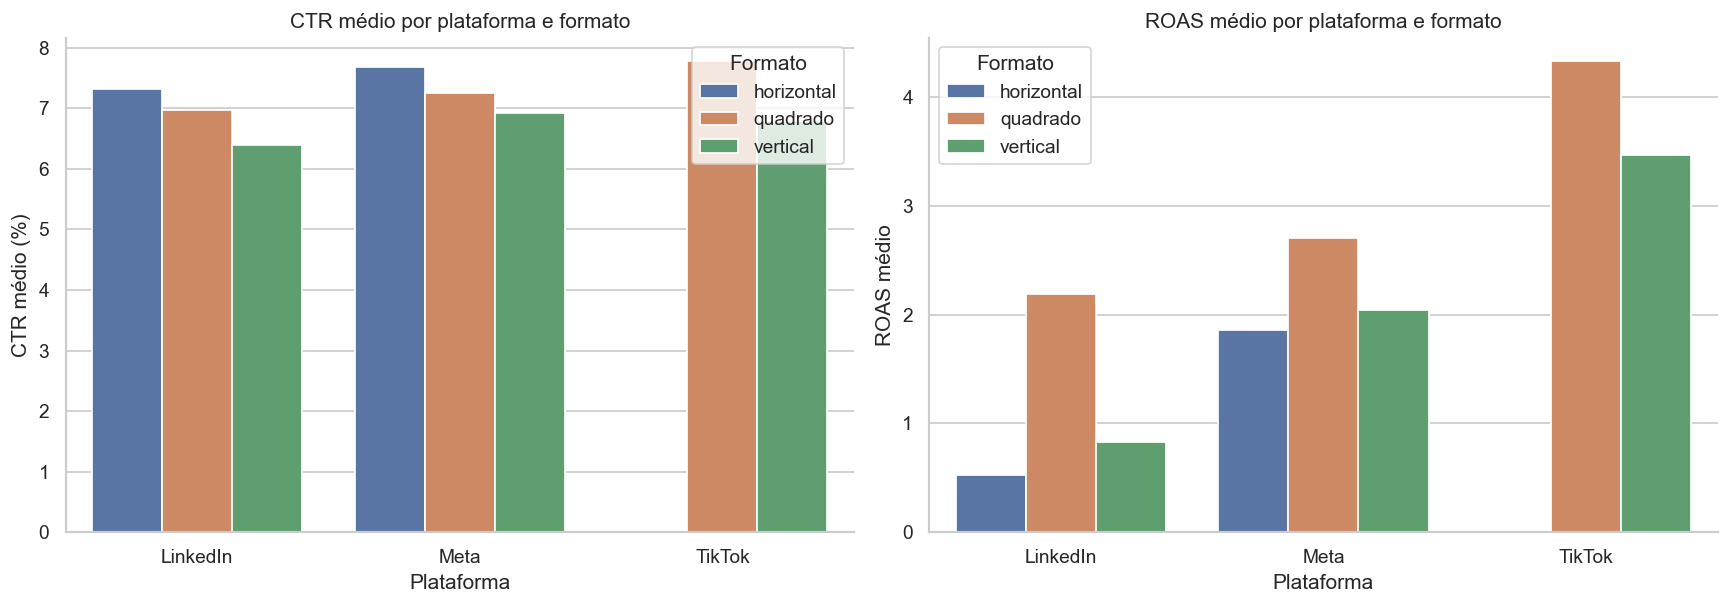

In [82]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

# CTR por plataforma e formato
sns.barplot(
    data=resumo_formatos,
    x="platform",
    y="ctr_percentual",
    hue="format",
    ax=axes[0]
)

axes[0].set_title("CTR médio por plataforma e formato")
axes[0].set_xlabel("Plataforma")
axes[0].set_ylabel("CTR médio (%)")
axes[0].legend(title="Formato")

# ROAS por plataforma e formato
sns.barplot(
    data=resumo_formatos,
    x="platform",
    y="roas_medio",
    hue="format",
    ax=axes[1]
)

axes[1].set_title("ROAS médio por plataforma e formato")
axes[1].set_xlabel("Plataforma")
axes[1].set_ylabel("ROAS médio")
axes[1].legend(title="Formato")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "formato_por_plataforma.png",
    bbox_inches="tight"
)

plt.show()



### 3.3.1 - Interpretação

A análise revelou diferenças de performance entre formatos horizontais, quadrados e verticais nas plataformas estudadas.

**CTR**

No LinkedIn, o formato horizontal apresentou maior CTR médio (7,32%), seguido pelos formatos quadrado (6,98%) e vertical (6,40%).

No Meta, o formato horizontal também apresentou maior CTR médio (7,68%), enquanto o formato vertical registrou o menor valor (6,92%).

No TikTok, o formato quadrado apresentou maior CTR médio (7,78%) em comparação ao vertical (6,79%). Não foram observadas campanhas horizontais nessa plataforma.

**ROAS**

O formato quadrado apresentou o maior ROAS médio nas três plataformas:

- LinkedIn: 2,19;
- Meta: 2,70;
- TikTok: 4,33.

Esse padrão sugere uma associação positiva entre o formato quadrado e o retorno financeiro no dataset analisado.

**Limitações**

As quantidades de campanhas variam entre plataformas e formatos. No TikTok, por exemplo, existem apenas 24 campanhas quadradas, contra 152 verticais.

Além disso, as comparações não controlam diferenças de categoria, objetivo, orçamento ou público-alvo.

**Conclusão**

Os resultados sugerem que diferentes formatos podem apresentar vantagens dependendo da plataforma e da métrica analisada.

O formato com maior CTR nem sempre apresenta o maior ROAS, reforçando a importância de considerar o objetivo da campanha ao formular recomendações.

Essas associações devem ser tratadas como hipóteses para validação, e não como efeitos causais comprovados.


## 3.4 - Densidade de texto e performance por plataforma

Esta análise investiga a relação entre a quantidade de texto exibida no vídeo e as métricas de CTR e ROAS em cada plataforma.

O objetivo é identificar possíveis diferenças entre baixa, média e alta densidade de texto e avaliar se os padrões observados na análise agregada se mantêm entre Meta, TikTok e LinkedIn.


In [83]:
# Agrupar por plataforma e densidade de texto
resumo_texto = df.groupby(
    ["platform", "text_density"]
).agg(
    campanhas=("campaign_id", "count"),
    ctr_medio=("ctr", "mean"),
    roas_medio=("roas", "mean")
).reset_index()

# Converter CTR para percentual
resumo_texto["ctr_percentual"] = (
    resumo_texto["ctr_medio"] * 100
)

display(resumo_texto.round(3))


,platform,text_density,campanhas,ctr_medio,roas_medio,ctr_percentual
0,LinkedIn,high,22,0.068,0.734,6.816
1,LinkedIn,low,30,0.071,1.943,7.071
2,LinkedIn,medium,31,0.073,0.621,7.287
3,Meta,high,32,0.050,1.796,5.005
4,Meta,low,104,0.075,2.431,7.501
5,Meta,medium,105,0.076,2.040,7.636
6,TikTok,high,37,0.063,3.169,6.287
7,TikTok,low,45,0.074,4.212,7.356
8,TikTok,medium,94,0.070,3.453,6.965


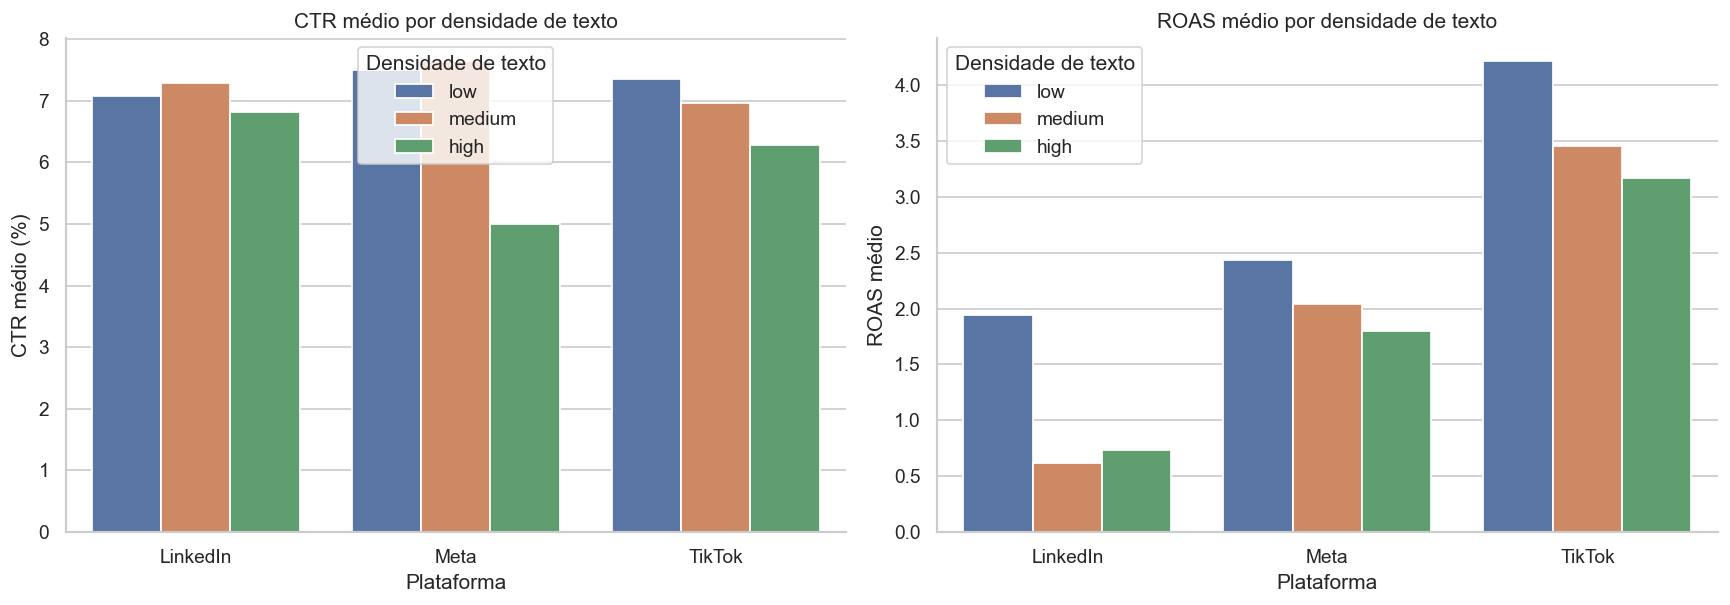

In [84]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

# Definir ordem das categorias
ordem_texto = ["low", "medium", "high"]

# CTR
sns.barplot(
    data=resumo_texto,
    x="platform",
    y="ctr_percentual",
    hue="text_density",
    hue_order=ordem_texto,
    ax=axes[0]
)

axes[0].set_title("CTR médio por densidade de texto")
axes[0].set_xlabel("Plataforma")
axes[0].set_ylabel("CTR médio (%)")
axes[0].legend(title="Densidade de texto")

# ROAS
sns.barplot(
    data=resumo_texto,
    x="platform",
    y="roas_medio",
    hue="text_density",
    hue_order=ordem_texto,
    ax=axes[1]
)

axes[1].set_title("ROAS médio por densidade de texto")
axes[1].set_xlabel("Plataforma")
axes[1].set_ylabel("ROAS médio")
axes[1].legend(title="Densidade de texto")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "densidade_texto_plataforma.png",
    bbox_inches="tight"
)

plt.show()


### 3.4.1 - Interpretação 

A análise revelou diferenças nas relações entre densidade de texto e performance entre Meta, TikTok e LinkedIn.

**CTR**

No LinkedIn, campanhas com densidade média apresentaram o maior CTR (7,29%), enquanto campanhas com alta densidade registraram o menor valor (6,82%).

No Meta, campanhas com densidade média apresentaram CTR de 7,64%, seguidas pela baixa (7,50%). A alta densidade apresentou resultado inferior (5,01%).

No TikTok, a baixa densidade apresentou o maior CTR (7,36%), seguida pela média (6,97%) e pela alta (6,29%).

**ROAS**

Campanhas com baixa densidade de texto apresentaram o maior ROAS médio nas três plataformas:

- LinkedIn: 1,94;
- Meta: 2,43;
- TikTok: 4,21.

Em comparação com campanhas de alta densidade, as diferenças relativas foram de aproximadamente 164,7%, 35,4% e 32,9%, respectivamente.

**Principal insight**

A baixa densidade de texto apresenta associação positiva com o retorno financeiro nas três plataformas, embora a relação com CTR varie.

Esse resultado sugere que a quantidade de texto exibida nos criativos pode ser um atributo relevante para orientar recomendações de melhoria.

**Limitações**

As comparações são descritivas e não controlam possíveis diferenças de categoria, objetivo, público-alvo ou investimento.

As diferenças observadas não devem ser interpretadas como efeitos causais da redução de texto.


## 3.5 - Conclusões

As análises indicam que características associadas a bons resultados em uma plataforma não necessariamente apresentam as mesmas relações com performance em outras.

**Principais descobertas:**

1. **Hook:** está associado a CTR médio maior nas três plataformas, mas a relação com ROAS varia. No TikTok, campanhas com hook apresentam ROAS superior; no Meta e LinkedIn, apresentam ROAS inferior.

2. **Formato:** o formato quadrado apresentou o maior ROAS médio nas três plataformas. Entretanto, os formatos com maior CTR variaram, e não existem campanhas horizontais no TikTok no dataset analisado.

3. **Densidade de texto:** a baixa densidade apresentou o maior ROAS médio nas três plataformas, enquanto os padrões de CTR foram diferentes.

4. **Diferenças gerais de performance:** as plataformas apresentaram CTR médio semelhante, mas diferenças expressivas em ROAS, conversões e engajamento.

**Conclusão geral**

Os resultados reforçam que a análise da performance de criativos deve considerar simultaneamente a plataforma, o objetivo da campanha e a métrica de interesse.

Para o Klike, isso sugere que um sistema de recomendações deve evitar regras universais e priorizar sugestões contextualizadas, fundamentadas nos padrões observados em campanhas comparáveis.

As associações identificadas constituem hipóteses de otimização, que precisam ser validadas por experimentos controlados antes de serem tratadas como ganhos esperados.


# 4 - Visualizações para marketing

Esta seção reúne três visualizações selecionadas das análises anteriores, priorizando resultados que possam orientar decisões de marketing.

Os gráficos foram escolhidos por sua capacidade de comunicar:

1. A relação entre características dos criativos e CTR;
2. As diferenças na relação entre hook e performance por plataforma;
3. A associação entre densidade de texto e ROAS.

As visualizações apresentam evidências descritivas e devem ser utilizadas para formular hipóteses de otimização, não para prometer ganhos causais.


## 4.1 - Características dos criativos e CTR

![CTR por característica](../img/ctr_atributos.png)

**Insight:** a presença de hook está associada ao maior aumento relativo de CTR entre os atributos binários analisados.